# AuraLearn Adaptive Reminder Evaluation

This notebook compares the **actual LinUCB implementation** in the `HT_Further_Development` branch with the repository's rule-based `AdaptiveScheduler` using reproducible synthetic scenarios.

**Important:** all results are simulated, not measured student outcomes. The response model is an explicit assumption for experimentation, not evidence of real-world learning improvement.

## 1. Clone the branch and configure Python imports

Run this first. It downloads the GitHub branch into the Colab runtime and adds the backend folder to `sys.path`. It does not push or modify anything on GitHub.

In [1]:
from pathlib import Path
import os, subprocess, sys

REPO_URL = "https://github.com/Five-Gang/R26-SE-022.git"
BRANCH = "HT_Further_Development"
REPO_DIR = Path("/content/R26-SE-022")

if REPO_DIR.exists() and not (REPO_DIR / ".git").exists():
    raise RuntimeError(f"{REPO_DIR} exists but is not a Git repository. Remove it and rerun.")
if not (REPO_DIR / ".git").exists():
    subprocess.run(["git", "clone", "--single-branch", "--branch", BRANCH, REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", BRANCH], check=True)

BACKEND = REPO_DIR / "adaptive-reminder-system" / "backend"
if not (BACKEND / "app").is_dir():
    raise FileNotFoundError(f"Backend app package not found: {BACKEND / 'app'}")
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))
os.chdir(BACKEND)

print("Branch:", BRANCH)
print("Backend:", BACKEND)
print("App package exists:", (BACKEND / "app").is_dir())

Branch: HT_Further_Development
Backend: /content/R26-SE-022/adaptive-reminder-system/backend
App package exists: True


## 2. Install lightweight dependencies

The simulation needs NumPy, pandas, and Matplotlib. It does not connect to MongoDB or run FastAPI.

In [2]:
%pip -q install numpy pandas matplotlib

## 3. Import and verify the actual repository classes

`ReminderAction` is defined in `app.models.bandit`, not `app.models.adaptive_scheduler`. The rule scheduler's `SEND_NOW` result is mapped to the bandit's `SEND` action for comparison.

In [3]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from app.models.bandit import BanditContext, LinUCB, ReminderAction
from app.models.adaptive_scheduler import AdaptiveScheduler

ACTIONS = ReminderAction.ALL
REWARDS = {"ACCEPTED": 1.0, "SNOOZED": 0.0, "DISMISSED": -1.0}
print("LinUCB source:", inspect.getfile(LinUCB))
print("Rule scheduler source:", inspect.getfile(AdaptiveScheduler))
print("Actions:", ACTIONS)
assert LinUCB().dimension == 10
print("Ten-feature LinUCB verified.")

LinUCB source: /content/R26-SE-022/adaptive-reminder-system/backend/app/models/bandit.py
Rule scheduler source: /content/R26-SE-022/adaptive-reminder-system/backend/app/models/adaptive_scheduler.py
Actions: ('SEND', 'DELAY', 'SKIP')
Ten-feature LinUCB verified.


## 4. Generate reproducible synthetic contexts

The ten features match the backend context contract. `time_since_reminder` is normalized to `[0, 1]`. A pre-generated response random number lets both policies see the same underlying random draw for each scenario.

In [4]:
def make_scenarios(seed=2026, n_students=120, steps_per_student=80):
    rng = np.random.default_rng(seed)
    rows = []
    for sid in range(n_students):
        receptiveness = float(rng.beta(5, 3))
        for step in range(steps_per_student):
            readiness = float(rng.beta(5, 2))
            retention = float(rng.beta(2.5, 3.5))
            priority = float(rng.beta(3, 2))
            hour = float(rng.uniform(0, 24))
            angle = 2 * np.pi * hour / 24
            rows.append({
                "student_id": sid, "step": step,
                "readiness_score": readiness,
                "retention_probability": retention,
                "priority_score": priority,
                "time_sin": float(np.sin(angle)), "time_cos": float(np.cos(angle)),
                "time_since_reminder": float(rng.uniform(0, 1)),
                "acceptance_rate": 0.0, "dismissal_rate": 0.0,
                "engagement_score": float(np.clip(.55 * readiness + .45 * rng.random(), 0, 1)),
                "receptiveness": receptiveness,
                "response_uniform": float(rng.random())
            })
    return pd.DataFrame(rows)

SCENARIOS = make_scenarios()
print(f"{len(SCENARIOS):,} scenarios across {SCENARIOS.student_id.nunique()} synthetic students.")
display(SCENARIOS.head())

9,600 scenarios across 120 synthetic students.


,student_id,step,readiness_score,retention_probability,priority_score,time_sin,time_cos,time_since_reminder,acceptance_rate,dismissal_rate,engagement_score,receptiveness,response_uniform
0,0,0,0.826834,0.279558,0.576482,0.318678,-0.947863,0.338812,0.0,0.0,0.579813,0.837069,0.226333
1,0,1,0.728232,0.612500,0.663993,-0.955863,0.293814,0.606710,0.0,0.0,0.555823,0.837069,0.946820
2,0,2,0.735068,0.458485,0.374761,-0.993062,-0.117596,0.548483,0.0,0.0,0.683964,0.837069,0.372144
3,0,3,0.518127,0.560214,0.750915,0.360724,0.932673,0.358231,0.0,0.0,0.613499,0.837069,0.314238
4,0,4,0.799416,0.538538,0.439461,0.079317,-0.996849,0.092889,0.0,0.0,0.445465,0.837069,0.604316


## 5. Context, baseline, and synthetic response assumptions

These response probabilities are made up for simulation and are not trained on real student data.

In [5]:
def context_from_row(row):
    return BanditContext(
        readiness_score=float(row["readiness_score"]),
        retention_probability=float(row["retention_probability"]),
        priority_score=float(row["priority_score"]),
        time_sin=float(row["time_sin"]), time_cos=float(row["time_cos"]),
        time_since_reminder=float(row["time_since_reminder"]),
        acceptance_rate=float(row["acceptance_rate"]),
        dismissal_rate=float(row["dismissal_rate"]),
        engagement_score=float(row["engagement_score"]), bias=1.0
    )

def rule_baseline(row, scheduler):
    r = float(row["readiness_score"])
    level = "HIGH" if r >= .67 else ("MEDIUM" if r >= .38 else "LOW")
    result = scheduler.decide_reminder_action(
        readiness_level=level,
        retention_probability=float(row["retention_probability"]),
        priority_score=float(row["priority_score"])
    )
    return {"SEND_NOW": ReminderAction.SEND,
            "DELAY": ReminderAction.DELAY,
            "SKIP": ReminderAction.SKIP}[result]

def simulated_response(row, action):
    if action == ReminderAction.SKIP:
        return None
    readiness = float(row["readiness_score"])
    engagement = float(row["engagement_score"])
    receptive = float(row["receptiveness"])
    if action == ReminderAction.SEND:
        p_accept = np.clip(.12 + .38*readiness + .20*engagement + .20*receptive, .05, .95)
    else:
        p_accept = np.clip(.16 + .28*readiness + .16*engagement + .20*receptive, .05, .90)
    u = float(row["response_uniform"])
    if u < p_accept: return "ACCEPTED"
    if u < p_accept + .18: return "SNOOZED"
    return "DISMISSED"

assert context_from_row(SCENARIOS.iloc[0]).vector().shape == (10,)
print("Context validation passed.")

Context validation passed.


## 6. Run rule-based and LinUCB policies on identical scenarios

The LinUCB policy updates only when the synthetic reminder has a response; `SKIP` generates no feedback. The fixed rule-based baseline does not learn. This experiment does not simulate MongoDB, actual delivery, or duplicate-reminder behavior.

In [6]:
def run_policy(policy_name, scenarios, alpha=0.5):
    # Match the backend design: each student has an independent LinUCB policy.
    bandits = {}
    scheduler = AdaptiveScheduler()
    history = {}
    records = []
    for row in scenarios.to_dict(orient="records"):
        sid = int(row["student_id"])
        hist = history.setdefault(sid, {"accepted": 0, "dismissed": 0, "answered": 0})
        x = dict(row)
        x["acceptance_rate"] = hist["accepted"]/hist["answered"] if hist["answered"] else 0.0
        x["dismissal_rate"] = hist["dismissed"]/hist["answered"] if hist["answered"] else 0.0
        context = context_from_row(x)
        scores, fallback = {}, 0
        if policy_name == "rule_based":
            action = rule_baseline(x, scheduler)
        elif policy_name == "linucb":
            bandit = bandits.setdefault(sid, LinUCB(alpha=alpha))
            try:
                scores = bandit.score_actions(context, ACTIONS)
                action = bandit.select_action(context, ACTIONS)
            except (ValueError, KeyError, TypeError, np.linalg.LinAlgError):
                fallback = 1
                action = rule_baseline(x, scheduler)
        else:
            raise ValueError(f"Unknown policy: {policy_name}")

        outcome = simulated_response(x, action)
        reward = np.nan if outcome is None else REWARDS[outcome]
        if policy_name == "linucb" and outcome is not None and not fallback:
            bandits[sid].update(action, context, float(reward))
        if outcome is not None:
            hist["answered"] += 1
            hist["accepted"] += int(outcome == "ACCEPTED")
            hist["dismissed"] += int(outcome == "DISMISSED")
        records.append({
            "policy": policy_name, "student_id": sid, "step": int(row["step"]),
            "action": action, "outcome": outcome or "NO_RESPONSE_SKIPPED",
            "reward": reward, "fallback": fallback, "scores": scores
        })
    return pd.DataFrame(records)

## 7. Summarize metrics

Response rates use only decisions that received a response. Cumulative reward sums the configured rewards for responses; skipped decisions are counted separately.

In [18]:
def summarize(group):
    responded = group[
        group["outcome"].isin(
            ["ACCEPTED", "SNOOZED", "DISMISSED"]
        )
    ]

    return pd.Series({
        "decisions": len(group),

        "send_count": int(
            (group.action == ReminderAction.SEND).sum()
        ),

        "delay_count": int(
            (group.action == ReminderAction.DELAY).sum()
        ),

        "skip_count": int(
            (group.action == ReminderAction.SKIP).sum()
        ),

        "acceptance_rate": (
            (responded.outcome == "ACCEPTED").mean()
            if len(responded) else np.nan
        ),

        "dismissal_rate": (
            (responded.outcome == "DISMISSED").mean()
            if len(responded) else np.nan
        ),

        "cumulative_reward": float(
            responded.reward.sum()
        ),

        "mean_reward_per_response": (
            float(responded.reward.mean())
            if len(responded) else np.nan
        ),

        # Skipped decisions contribute zero reward.
        "mean_reward_per_decision": (
            float(group["reward"].fillna(0.0).sum() / len(group))
            if len(group) else np.nan
        ),

        "fallback_count": int(
            group.fallback.sum()
        )
    })

# Generate the results by running both policies on the simulated scenarios
results = pd.concat([
    run_policy("rule_based", SCENARIOS),
    run_policy("linucb", SCENARIOS)
], ignore_index=True)

summary = results.groupby("policy", sort=False).apply(summarize).round(4)
display(summary)

/tmp/ipykernel_669/2941411839.py:59: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = results.groupby("policy", sort=False).apply(summarize).round(4)


,decisions,send_count,delay_count,skip_count,acceptance_rate,dismissal_rate,cumulative_reward,mean_reward_per_response,mean_reward_per_decision,fallback_count
policy,,,,,,,,,,
rule_based,9600.0,3482.0,5824.0,294.0,0.6178,0.2011,3878.0,0.4167,0.4040,0.0
linucb,9600.0,1093.0,794.0,7713.0,0.6280,0.1892,828.0,0.4388,0.0862,0.0


## 8. Plot the results

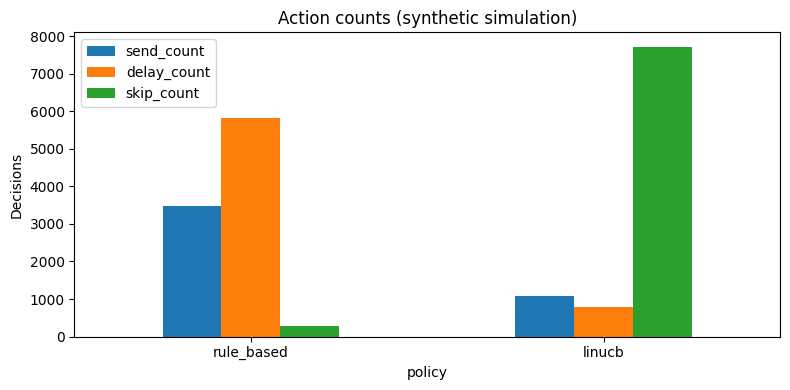

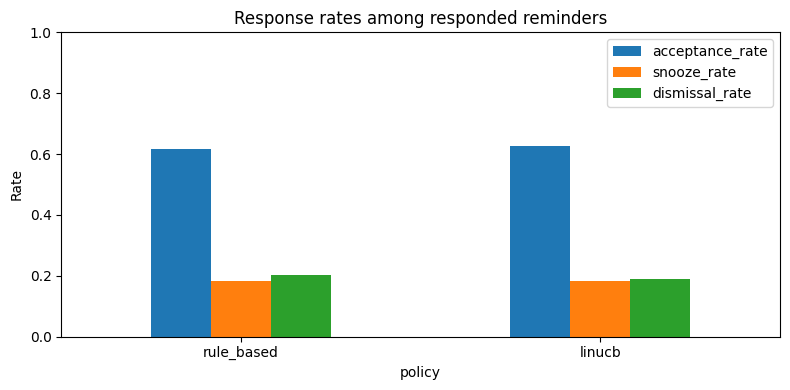

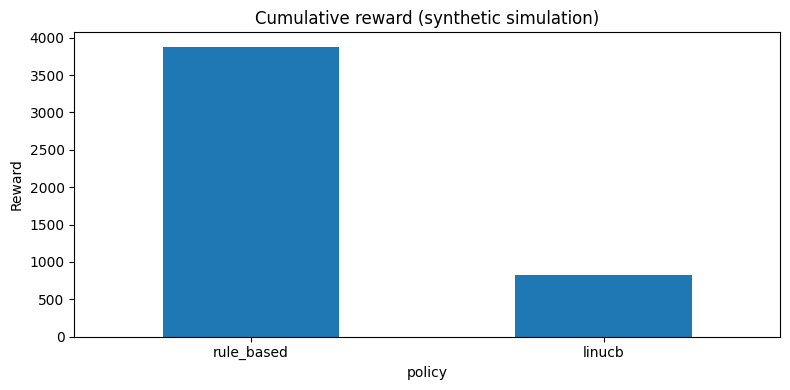

In [19]:
# Calculate snooze_rate dynamically for the plot since it was removed from the summary DataFrame
plot_summary = summary.copy()
plot_summary["snooze_rate"] = 1.0 - plot_summary["acceptance_rate"] - plot_summary["dismissal_rate"]

plot_summary[["send_count", "delay_count", "skip_count"]].plot(kind="bar", figsize=(8,4), title="Action counts (synthetic simulation)")
plt.ylabel("Decisions"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

plot_summary[["acceptance_rate", "snooze_rate", "dismissal_rate"]].plot(kind="bar", figsize=(8,4), title="Response rates among responded reminders")
plt.ylabel("Rate"); plt.ylim(0,1); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

plot_summary["cumulative_reward"].plot(kind="bar", figsize=(8,4), title="Cumulative reward (synthetic simulation)")
plt.ylabel("Reward"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 9. Repeat with multiple seeds

Multiple seeds help show how sensitive the results are to the particular simulated sample. They do not turn synthetic results into real-user evidence.

In [20]:
def evaluate_seed(seed, n_students=60, steps_per_student=50):
    scenarios = make_scenarios(seed=seed, n_students=n_students, steps_per_student=steps_per_student)
    both = pd.concat([
        run_policy("rule_based", scenarios),
        run_policy("linucb", scenarios)
    ], ignore_index=True)
    return both.groupby("policy", sort=False).apply(summarize).reset_index()

multi = pd.concat([evaluate_seed(s) for s in [11, 22, 33, 44, 55]], ignore_index=True)
metrics = ["acceptance_rate", "dismissal_rate", "cumulative_reward", "send_count", "delay_count", "skip_count"]
display(multi.groupby("policy")[metrics].agg(["mean", "std"]).round(4))

/tmp/ipykernel_669/3854561907.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return both.groupby("policy", sort=False).apply(summarize).reset_index()
/tmp/ipykernel_669/3854561907.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return both.groupby("policy", sort=False).apply(summarize).reset_index()
/tmp/ipykernel_669/3854561907.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the group

acceptance_rate         dismissal_rate         cumulative_reward  \
                      mean     std           mean     std              mean   
policy                                                                        
linucb              0.6319  0.0035         0.1934  0.0119             352.8   
rule_based          0.6117  0.0099         0.2064  0.0100            1177.6   

                    send_count          delay_count          skip_count  \
                std       mean      std        mean      std       mean   
policy                                                                    
linucb      16.6193      450.0  34.9714       355.0  51.7349     2195.0   
rule_based  58.8201     1051.8  23.5733      1853.2  22.1179       95.0   

                     
                std  
policy               
linucb      39.6485  
rule_based  13.2665

## 10. Export tables for your report

The exported CSV files are explicitly synthetic. Do not present them as measured student outcomes.

In [21]:
from pathlib import Path
OUT_DIR = Path("/content/auraLearn_evaluation_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT_DIR / "synthetic_policy_decisions.csv", index=False)
summary.to_csv(OUT_DIR / "synthetic_policy_summary.csv")
multi.to_csv(OUT_DIR / "synthetic_multi_seed_summary.csv", index=False)
print("Saved:")
for p in sorted(OUT_DIR.iterdir()):
    print("-", p)
try:
    from google.colab import files
    files.download(str(OUT_DIR / "synthetic_policy_summary.csv"))
except ImportError:
    print("Not in Google Colab; files remain in OUT_DIR.")

Saved:
- /content/auraLearn_evaluation_outputs/synthetic_multi_seed_summary.csv
- /content/auraLearn_evaluation_outputs/synthetic_policy_decisions.csv
- /content/auraLearn_evaluation_outputs/synthetic_policy_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>